<a href="https://colab.research.google.com/github/komalsanjaypawar17-sudo/membrane-fouling-prediction/blob/main/watertreatment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 OSMOFLO MEMBRANE FOULING PREDICTION - ANN BACKPROPAGATION 

[1] Dataset Preview (first 5 rows):
   Feed_Pressure_bar  Feed_TDS_mgL  Feed_Temperature_C  Flow_Rate_m3h  \
0          15.618102   1091.272721           30.165264      77.390084   
1          24.260715   1475.066187           15.491738      64.250502   
2          20.979909   1119.536695           15.442471      41.195085   
3          18.979877    810.458868           21.472204      37.792135   
4          12.340280    922.225549           24.772864      40.982194   

         pH  Turbidity_NTU  Recovery_Rate_%  Fouling_Risk  
0  6.851510       3.396245        46.355059             0  
1  6.179280       4.003739        65.689484             0  
2  7.024072       1.327293        48.337166             0  
3  6.778044       3.161883        52.538938             0  
4  7.692802       2.901555        49.841941             0  

Dataset shape: (600, 8)
Class distribution:
 Fouling_Risk
0    330
1    270
Name: count, dtype: int64



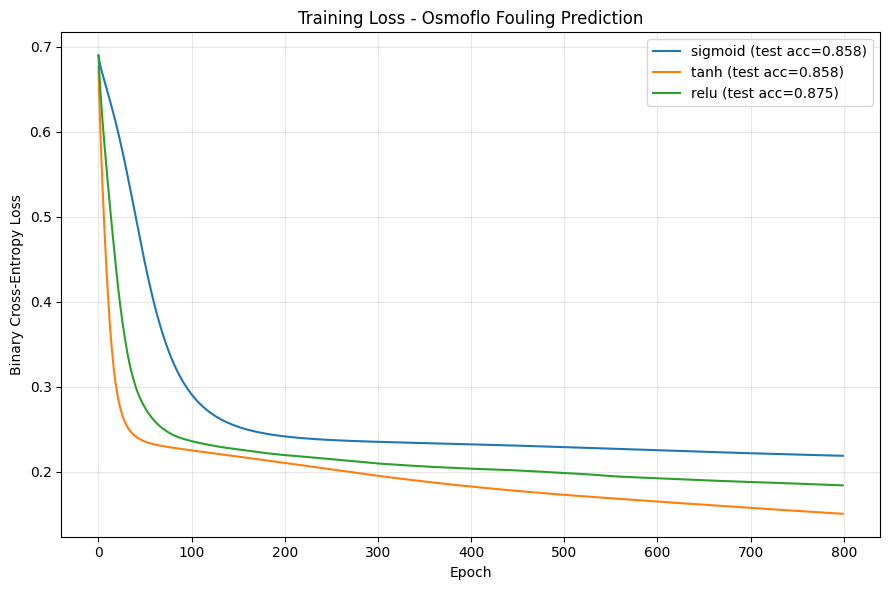


[3] Best Activation Function: 'relu' (Test Accuracy = 0.8750)

Confusion Matrix:
[[58  8]
 [ 7 47]]

Classification Report:
              precision    recall  f1-score   support

    Low Risk       0.89      0.88      0.89        66
   High Risk       0.85      0.87      0.86        54

    accuracy                           0.88       120
   macro avg       0.87      0.87      0.87       120
weighted avg       0.88      0.88      0.88       120


[4] Testing on a NEW Osmoflo plant reading:
  Input: Pressure=18.5 bar, TDS=3200 mg/L, Temp=27°C, Flow=55 m³/h, pH=7.4, Turbidity=3.8 NTU, Recovery=78%
  Predicted Probability of Fouling: 0.9984
  Result: HIGH FOULING RISK ⚠️


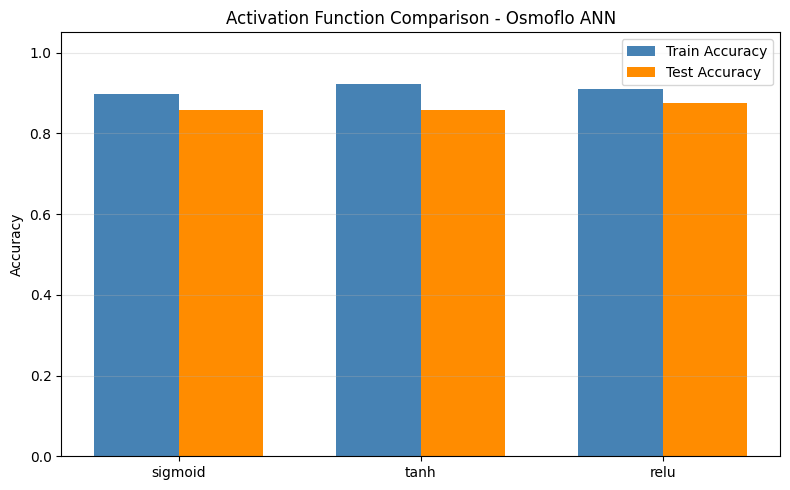


[5] Plots saved: osmof_loss_comparison.png, osmof_activation_comparison.png
Experiment completed successfully.


In [ ]:
"""
Lab Experiment 2: Artificial Neural Network with Backpropagation
Domain: Osmoflo Water Treatment / Desalination Plant
Task: Predict Membrane Fouling Risk (Low / High)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Set random seeds for reproducibility
np.random.seed(42)

# ============================================================
# STEP 1: CREATE IMAGINARY OSMOFLO DATASET
# ============================================================
# Features (realistic RO plant parameters):
#   - Feed_Pressure_bar      : Inlet pressure to RO membrane
#   - Feed_TDS_mgL           : Total Dissolved Solids in feed water
#   - Feed_Temperature_C     : Feed water temperature
#   - Flow_Rate_m3h          : Feed flow rate
#   - pH                     : Feed water pH
#   - Turbidity_NTU          : Feed turbidity
#   - Recovery_Rate_%        : System recovery percentage
# Target:
#   - Fouling_Risk : 1 = High fouling risk, 0 = Low fouling risk

def create_osmof_dataset(n_samples=600):
    np.random.seed(42)

    feed_pressure   = np.random.uniform(10, 25, n_samples)      # bar
    feed_tds        = np.random.uniform(500, 4000, n_samples)   # mg/L
    feed_temp       = np.random.uniform(15, 35, n_samples)      # °C
    flow_rate       = np.random.uniform(20, 80, n_samples)      # m3/h
    ph              = np.random.uniform(6.0, 8.5, n_samples)
    turbidity       = np.random.uniform(0.1, 5.0, n_samples)    # NTU
    recovery        = np.random.uniform(40, 85, n_samples)      # %

    # Rule-based fouling logic (to create realistic labels)
    score = (
        (feed_tds / 4000) * 0.35 +
        (turbidity / 5.0) * 0.30 +
        (recovery / 85) * 0.20 +
        (1 - feed_pressure / 25) * 0.15 +
        np.random.normal(0, 0.05, n_samples)  # noise
    )
    fouling_risk = (score > 0.55).astype(int)

    df = pd.DataFrame({
        "Feed_Pressure_bar": feed_pressure,
        "Feed_TDS_mgL": feed_tds,
        "Feed_Temperature_C": feed_temp,
        "Flow_Rate_m3h": flow_rate,
        "pH": ph,
        "Turbidity_NTU": turbidity,
        "Recovery_Rate_%": recovery,
        "Fouling_Risk": fouling_risk
    })
    return df


print("=" * 65)
print(" OSMOFLO MEMBRANE FOULING PREDICTION - ANN BACKPROPAGATION ")
print("=" * 65)

# Load dataset
df = create_osmof_dataset(600)
print("\n[1] Dataset Preview (first 5 rows):")
print(df.head())
print("\nDataset shape:", df.shape)
print("Class distribution:\n", df["Fouling_Risk"].value_counts())

# ============================================================
# STEP 2: PREPROCESSING
# ============================================================
X = df.drop("Fouling_Risk", axis=1).values
y = df["Fouling_Risk"].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# ============================================================
# STEP 3: NEURAL NETWORK FROM SCRATCH (Backpropagation)
# ============================================================
class NeuralNetwork:
    def __init__(self, n_input, n_hidden, n_output, activation="sigmoid", lr=0.1):
        self.lr = lr
        self.activation_name = activation

        # Xavier initialization
        self.W1 = np.random.randn(n_input, n_hidden) * np.sqrt(1.0 / n_input)
        self.b1 = np.zeros((1, n_hidden))
        self.W2 = np.random.randn(n_hidden, n_output) * np.sqrt(1.0 / n_hidden)
        self.b2 = np.zeros((1, n_output))

        self.loss_history = []

    # ---------------- Activation functions ----------------
    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def sigmoid_deriv(a):
        return a * (1.0 - a)

    @staticmethod
    def tanh(z):
        return np.tanh(z)

    @staticmethod
    def tanh_deriv(a):
        return 1.0 - a ** 2

    @staticmethod
    def relu(z):
        return np.maximum(0, z)

    @staticmethod
    def relu_deriv(a):
        return (a > 0).astype(float)

    def _activate(self, z):
        if self.activation_name == "sigmoid":
            return self.sigmoid(z)
        elif self.activation_name == "tanh":
            return self.tanh(z)
        elif self.activation_name == "relu":
            return self.relu(z)
        else:
            raise ValueError("Unknown activation")

    def _activate_deriv(self, a):
        if self.activation_name == "sigmoid":
            return self.sigmoid_deriv(a)
        elif self.activation_name == "tanh":
            return self.tanh_deriv(a)
        elif self.activation_name == "relu":
            return self.relu_deriv(a)
        else:
            raise ValueError("Unknown activation")

    # ---------------- Forward pass ----------------
    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = self._activate(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = self.sigmoid(self.z2)   # output layer = sigmoid (binary)
        return self.a2

    # ---------------- Backward pass ----------------
    def backward(self, X, y):
        m = X.shape[0]

        # Output layer error (BCE derivative with sigmoid output)
        dz2 = self.a2 - y                            # (m, 1)
        dW2 = (self.a1.T @ dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        # Hidden layer error
        da1 = dz2 @ self.W2.T                        # (m, hidden)
        dz1 = da1 * self._activate_deriv(self.a1)
        dW1 = (X.T @ dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Gradient descent update
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    # ---------------- Loss ----------------
    @staticmethod
    def binary_cross_entropy(y_true, y_pred):
        eps = 1e-9
        y_pred = np.clip(y_pred, eps, 1 - eps)
        return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

    # ---------------- Training ----------------
    def fit(self, X, y, epochs=500):
        for epoch in range(epochs):
            y_pred = self.forward(X)
            loss = self.binary_cross_entropy(y, y_pred)
            self.loss_history.append(loss)
            self.backward(X, y)

    # ---------------- Prediction ----------------
    def predict(self, X):
        probs = self.forward(X)
        return (probs > 0.5).astype(int)


# ============================================================
# STEP 4: TRAIN & COMPARE ACTIVATION FUNCTIONS
# ============================================================
activations = ["sigmoid", "tanh", "relu"]
results = {}

print("\n[2] Training ANN with different activation functions...\n")
print(f"{'Activation':<12}{'Train Acc':<12}{'Test Acc':<12}{'Final Loss':<12}")
print("-" * 50)

plt.figure(figsize=(9, 6))

for act in activations:
    np.random.seed(42)
    nn = NeuralNetwork(n_input=X_train.shape[1], n_hidden=8,
                       n_output=1, activation=act, lr=0.5)
    nn.fit(X_train, y_train, epochs=800)

    train_acc = accuracy_score(y_train, nn.predict(X_train))
    test_acc  = accuracy_score(y_test,  nn.predict(X_test))
    final_loss = nn.loss_history[-1]

    results[act] = {
        "model": nn,
        "train_acc": train_acc,
        "test_acc": test_acc,
        "loss": final_loss,
        "history": nn.loss_history
    }

    print(f"{act:<12}{train_acc:<12.4f}{test_acc:<12.4f}{final_loss:<12.4f}")
    plt.plot(nn.loss_history, label=f"{act} (test acc={test_acc:.3f})")

plt.title("Training Loss - Osmoflo Fouling Prediction")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("osmof_loss_comparison.png", dpi=100)
plt.show()

# ============================================================
# STEP 5: DETAILED REPORT FOR BEST MODEL
# ============================================================
best_act = max(results, key=lambda k: results[k]["test_acc"])
print(f"\n[3] Best Activation Function: '{best_act}' "
      f"(Test Accuracy = {results[best_act]['test_acc']:.4f})")

best_model = results[best_act]["model"]
y_pred = best_model.predict(X_test).flatten()
y_true = y_test.flatten()

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Low Risk", "High Risk"]))

# ============================================================
# STEP 6: SAMPLE PREDICTION ON NEW OSMOFLO READING
# ============================================================
print("\n[4] Testing on a NEW Osmoflo plant reading:")
new_sample = np.array([[18.5, 3200, 27.0, 55.0, 7.4, 3.8, 78.0]])  # high-risk style
new_sample_scaled = scaler.transform(new_sample)
prob = best_model.forward(new_sample_scaled)[0, 0]
pred = "HIGH FOULING RISK ⚠️" if prob > 0.5 else "LOW FOULING RISK ✅"
print(f"  Input: Pressure=18.5 bar, TDS=3200 mg/L, Temp=27°C, "
      f"Flow=55 m³/h, pH=7.4, Turbidity=3.8 NTU, Recovery=78%")
print(f"  Predicted Probability of Fouling: {prob:.4f}")
print(f"  Result: {pred}")

# ============================================================
# STEP 7: BAR CHART COMPARISON
# ============================================================
plt.figure(figsize=(8, 5))
acts = list(results.keys())
train_accs = [results[a]["train_acc"] for a in acts]
test_accs  = [results[a]["test_acc"]  for a in acts]

x = np.arange(len(acts))
w = 0.35
plt.bar(x - w/2, train_accs, w, label="Train Accuracy", color="steelblue")
plt.bar(x + w/2, test_accs,  w, label="Test Accuracy",  color="darkorange")
plt.xticks(x, acts)
plt.ylabel("Accuracy")
plt.title("Activation Function Comparison - Osmoflo ANN")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("osmof_activation_comparison.png", dpi=100)
plt.show()

print("\n[5] Plots saved: osmof_loss_comparison.png, osmof_activation_comparison.png")
print("Experiment completed successfully.")